<a href="https://colab.research.google.com/github/vsarvagna21-code/Handwritten-Digit-Recognition-Using-CNN/blob/main/CLA_3_FINAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

from google.colab import files

uploaded = files.upload()


Saving digit-recognizer.zip to digit-recognizer.zip


In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)


All libraries imported successfully!
TensorFlow version: 2.21.0


In [4]:
import zipfile

# Extract the uploaded zip archive
with zipfile.ZipFile('digit-recognizer.zip', 'r') as zip_ref:
    zip_ref.extractall('.')

train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")

print("Training dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

display(train_df.head())

Training dataset shape: (42000, 785)
Testing dataset shape: (28000, 784)


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


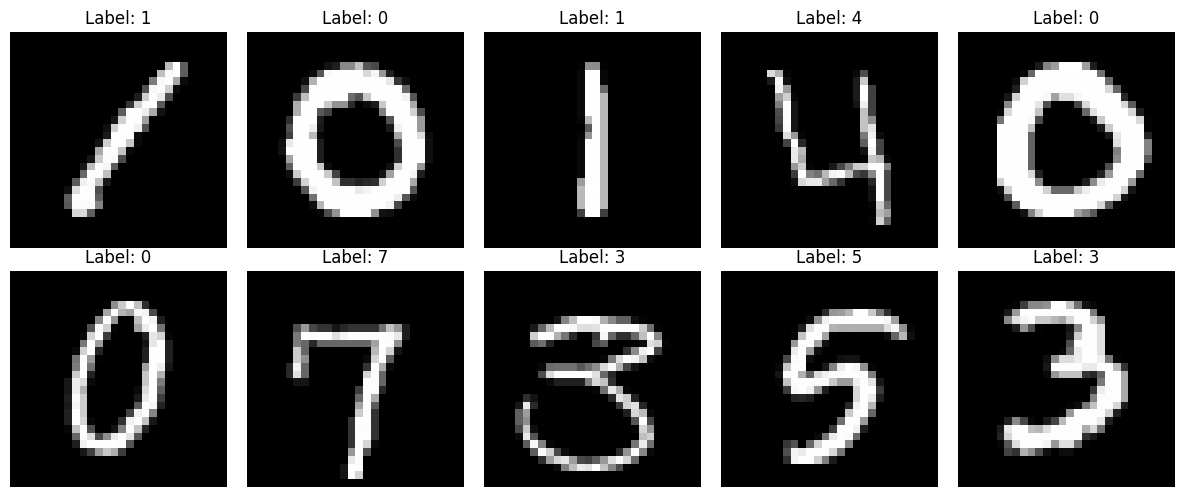

In [5]:

X = train_df.drop("label", axis=1).values
y = train_df["label"].values

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X[i].reshape(28, 28), cmap="gray")
    plt.title("Label: " + str(y[i]))
    plt.axis("off")

plt.tight_layout()
plt.show()


In [6]:

# Normalize pixel values
X = X.astype("float32") / 255.0
X_test = test_df.values.astype("float32") / 255.0

# Reshape images for CNN
X = X.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

# Split training and validation data
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)


Training data: (33600, 28, 28, 1)
Validation data: (8400, 28, 28, 1)
Testing data: (28000, 28, 28, 1)


In [7]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

model = Sequential([
    Conv2D(32, (3, 3), activation="relu",
           input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation="relu"),
    Dropout(0.3),

    Dense(10, activation="softmax")
])

model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully!")


CNN model compiled successfully!


In [10]:

from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 32s 59ms/step - accuracy: 0.9101 - loss: 0.2884 - val_accuracy: 0.9742 - val_loss: 0.0861
Epoch 2/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 31s 59ms/step - accuracy: 0.9719 - loss: 0.0905 - val_accuracy: 0.9799 - val_loss: 0.0649
Epoch 3/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 30s 57ms/step - accuracy: 0.9802 - loss: 0.0626 - val_accuracy: 0.9851 - val_loss: 0.0516
Epoch 4/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 30s 57ms/step - accuracy: 0.9850 - loss: 0.0492 - val_accuracy: 0.9857 - val_loss: 0.0471
Epoch 5/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 33s 63ms/step - accuracy: 0.9879 - loss: 0.0393 - val_accuracy: 0.9880 - val_loss: 0.0418
Epoch 6/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 30s 57ms/step - accuracy: 0.9895 - loss: 0.0331 - val_accuracy: 0.9881 - val_loss: 0.0429
Epoch 7/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 42s 58ms/step - accuracy: 0.9904 - loss: 0.0292 - val_accuracy: 0.9874 - val_loss: 0.0438
Epoch 8/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 30s 57ms/step - accuracy: 0.9909 - loss: 0.0269 - 

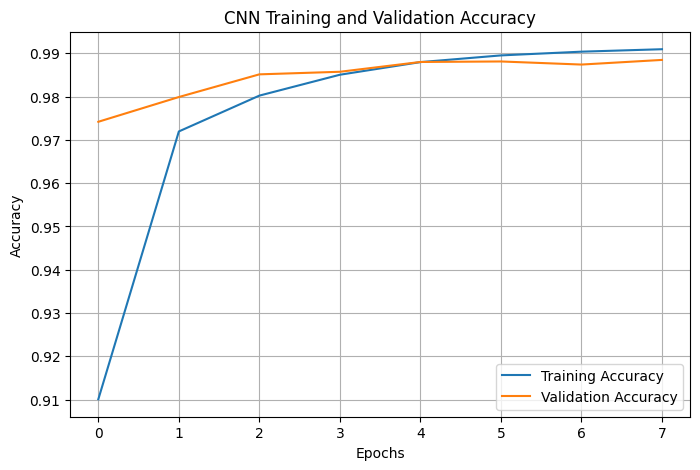

In [11]:

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()


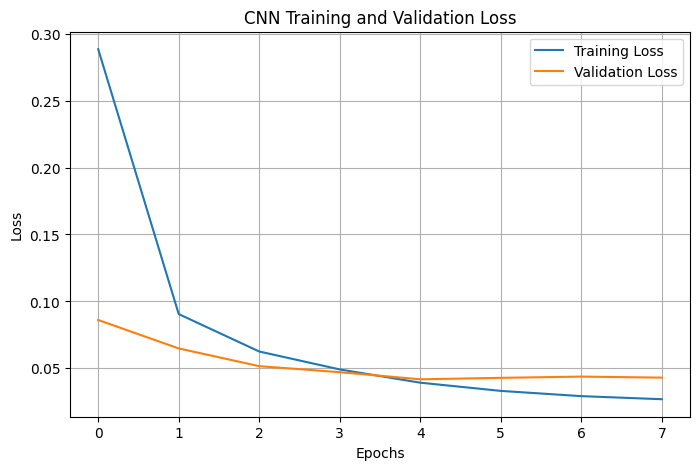

In [12]:

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("CNN Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()


In [13]:

test_loss, test_accuracy = model.evaluate(
    X_val, y_val, verbose=0
)

print("Validation Loss:", round(test_loss, 4))
print("Validation Accuracy:", round(test_accuracy * 100, 2), "%")


Validation Loss: 0.0418
Validation Accuracy: 98.8 %


In [14]:

import numpy as np

y_pred_prob = model.predict(X_val)

y_pred = np.argmax(y_pred_prob, axis=1)

print("Predictions generated successfully!")
print("Actual labels:", y_val[:10])
print("Predicted labels:", y_pred[:10])


263/263 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step
Predictions generated successfully!
Actual labels: [1 8 6 9 5 7 6 7 7 7]
Predicted labels: [1 8 6 8 5 7 6 7 7 7]


In [15]:

from sklearn.metrics import classification_report

print("CNN Classification Report")

print(
    classification_report(
        y_val,
        y_pred,
        digits=4
    )
)


CNN Classification Report
              precision    recall  f1-score   support

           0     0.9951    0.9855    0.9903       827
           1     0.9968    0.9957    0.9963       937
           2     0.9857    0.9928    0.9893       835
           3     0.9918    0.9782    0.9850       870
           4     0.9901    0.9877    0.9889       814
           5     0.9817    0.9881    0.9849       759
           6     0.9952    0.9927    0.9939       827
           7     0.9965    0.9830    0.9897       880
           8     0.9804    0.9852    0.9828       813
           9     0.9651    0.9905    0.9776       838

    accuracy                         0.9880      8400
   macro avg     0.9879    0.9879    0.9879      8400
weighted avg     0.9881    0.9880    0.9880      8400



<Figure size 900x700 with 0 Axes>

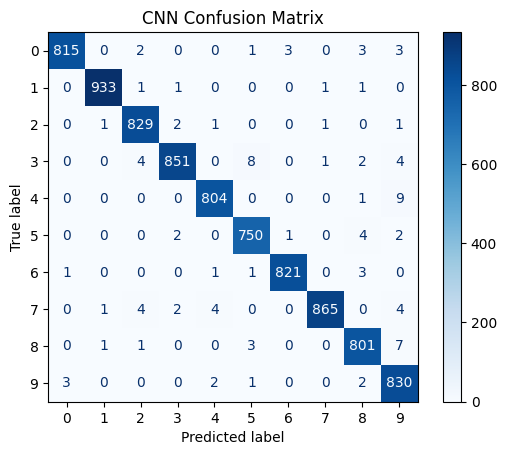

In [16]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_val, y_pred)

plt.figure(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
)

disp.plot(cmap="Blues", values_format="d")
plt.title("CNN Confusion Matrix")
plt.show()


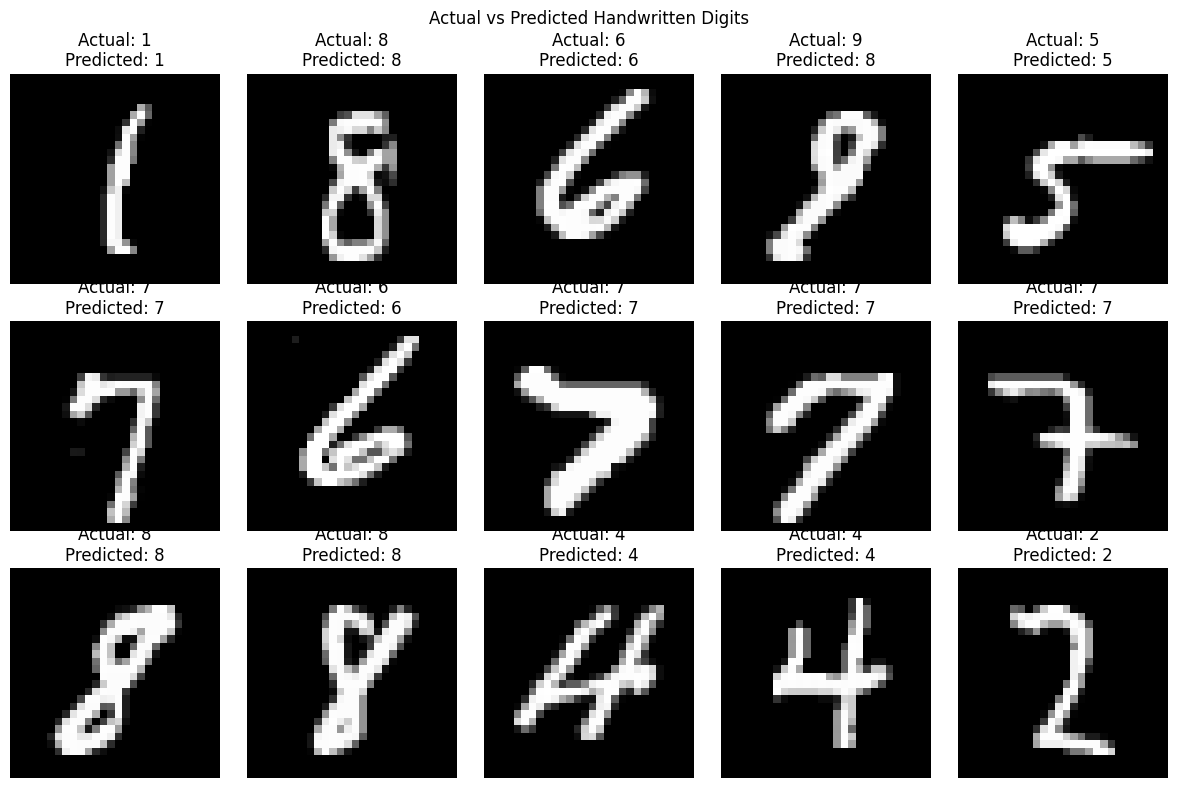

In [17]:

plt.figure(figsize=(12, 8))

for i in range(15):
    plt.subplot(3, 5, i + 1)

    plt.imshow(X_val[i].reshape(28, 28), cmap="gray")

    plt.title(
        f"Actual: {y_val[i]}\nPredicted: {y_pred[i]}"
    )

    plt.axis("off")

plt.suptitle("Actual vs Predicted Handwritten Digits")
plt.tight_layout()
plt.show()


In [18]:

test_predictions_prob = model.predict(X_test)

test_predictions = np.argmax(
    test_predictions_prob,
    axis=1
)

print("Test predictions completed!")
print("Total predictions:", len(test_predictions))

print("First 20 predictions:")
print(test_predictions[:20])


875/875 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step
Test predictions completed!
Total predictions: 28000
First 20 predictions:
[2 0 9 9 3 7 0 3 0 3 5 7 4 0 4 3 3 1 9 0]


In [19]:

submission = pd.DataFrame({
    "ImageId": np.arange(1, len(test_predictions) + 1),
    "Label": test_predictions
})

submission.to_csv(
    "submission.csv",
    index=False
)

print("Submission file created successfully!")
display(submission.head(10))


Submission file created successfully!


,ImageId,Label
0,1,2
1,2,0
2,3,9
3,4,9
4,5,3
5,6,7
6,7,0
7,8,3
8,9,0
9,10,3


In [20]:

model.save("handwritten_digit_cnn.keras")

print("CNN model saved successfully!")


CNN model saved successfully!


In [21]:

from google.colab import files

files.download("handwritten_digit_cnn.keras")
files.download("submission.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>